# Model 4: Heteroskedastic Hierarchical Bayesian Model

This notebook extends Model 3 by allowing the residual noise to differ by product.

That matters when one product has more volatile sales than another. A single shared `sigma` can make uncertainty too wide for stable products and too narrow for volatile products.


- non-linear
- hierarchical
- local group-wise variance (good)

Not: sigma ~ product + product:unit_price
- quantity ~ s(unit_price, by = product) + (1 | product)
- sigma   ~ s(unit_price, by = product) + (1 | product)

## Notebook setup

The sampling defaults are intentionally smaller than the script defaults so the notebooks are easier to run interactively. Increase `DRAWS`, `TUNE`, or `CHAINS` when you want more stable final inference.


In [37]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Keep Matplotlib/ArviZ cache files inside the project environment.
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".matplotlib-cache"))

FIGURES_DIR = PROJECT_ROOT / "figures"
MODELS_DIR = PROJECT_ROOT / "models"
FIGURES_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

# RANDOM_SEED = 123
# DRAWS = 500
# TUNE = 500
# CHAINS = 2
# TARGET_ACCEPT = 0.9

RANDOM_SEED = 123
DRAWS = 2000
TUNE = 2000
CHAINS = 4
CORES = 1
TARGET_ACCEPT = 0.9


In [38]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm

from utils.data_loader import load_sales_data

az.style.use("arviz-whitegrid")


In [39]:
sales_df = load_sales_data()
sales_df.head()


,product,quantity,unit_price
0,Standard iPhone Case,444,38.79
1,Standard iPhone Case,477,36.12
2,Standard iPhone Case,656,27.62
3,Standard iPhone Case,507,36.48
4,Standard iPhone Case,513,37.50


In [40]:
sales_df.info()
sales_df.describe(include="all")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 197 entries, 0 to 196
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   product     197 non-null    category
 1   quantity    197 non-null    int64   
 2   unit_price  197 non-null    float64 
dtypes: category(1), float64(1), int64(1)
memory usage: 3.5 KB


,product,quantity,unit_price
count,197,197.000000,197.000000
unique,2,NaN,NaN
top,Standard iPhone Case,NaN,NaN
freq,100,NaN,NaN
mean,NaN,440.137056,46.512437
std,NaN,115.559449,14.660253
min,NaN,160.000000,18.170000
25%,NaN,368.000000,35.030000
50%,NaN,444.000000,39.400000
75%,NaN,518.000000,60.630000


A quick plot helps anchor the modeling problem. We are looking for the relationship between `unit_price` and `quantity`, while remembering that products may have different demand curves.


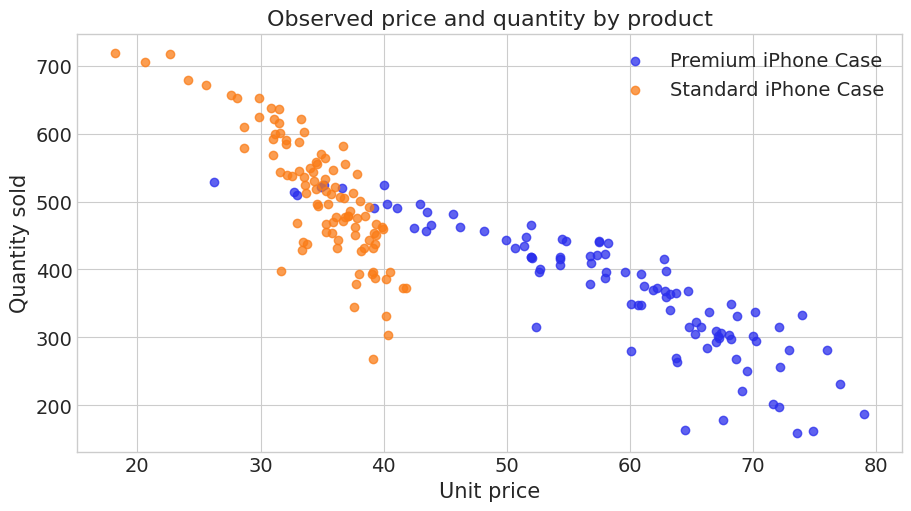

In [41]:
fig, ax = plt.subplots(figsize=(9, 5))
for product, group in sales_df.groupby("product", observed=True):
    ax.scatter(group["unit_price"], group["quantity"], alpha=0.75, label=str(product))
ax.set_xlabel("Unit price")
ax.set_ylabel("Quantity sold")
ax.set_title("Observed price and quantity by product")
ax.legend()
plt.show()


In [42]:
def standardise(values):
    values = np.asarray(values, dtype=float)
    mean = float(np.mean(values))
    std = float(np.std(values))
    if std == 0:
        raise ValueError("Cannot standardise a variable with zero variance.")
    return (values - mean) / std, mean, std


def prediction_summary(posterior_predictive, original_data, var_name="quantity_obs"):
    draws = posterior_predictive.posterior_predictive[var_name].values
    draws = draws.reshape(-1, draws.shape[-1])
    summary = pd.DataFrame({
        ".pred": np.mean(draws, axis=0),
        ".pred_lower_95": np.quantile(draws, 0.025, axis=0),
        ".pred_lower_66": np.quantile(draws, 0.17, axis=0),
        ".pred_upper_66": np.quantile(draws, 0.83, axis=0),
        ".pred_upper_95": np.quantile(draws, 0.975, axis=0),
    })
    return pd.concat([original_data.reset_index(drop=True), summary], axis=1)


def plot_predictions(predictions, title, facet=False):
    if not facet:
        plot_data = predictions.sort_values("unit_price")
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.fill_between(plot_data["unit_price"].to_numpy(), plot_data[".pred_lower_95"].to_numpy(), plot_data[".pred_upper_95"].to_numpy(), alpha=0.20, label="95% interval")
        ax.fill_between(plot_data["unit_price"].to_numpy(), plot_data[".pred_lower_66"].to_numpy(), plot_data[".pred_upper_66"].to_numpy(), alpha=0.35, label="66% interval")
        for product, group in plot_data.groupby("product", observed=True):
            ax.scatter(group["unit_price"], group["quantity"], alpha=0.70, label=str(product))
        ax.plot(plot_data["unit_price"], plot_data[".pred"], linewidth=2, color="black", label="Posterior predictive mean")
        ax.set_xlabel("Unit price")
        ax.set_ylabel("Quantity sold")
        ax.set_title(title)
        ax.legend(fontsize=8)
        plt.show()
        return

    products = list(predictions["product"].cat.categories if hasattr(predictions["product"], "cat") else sorted(predictions["product"].unique()))
    fig, axes = plt.subplots(1, len(products), figsize=(6 * len(products), 5), sharey=True)
    if len(products) == 1:
        axes = [axes]
    for ax, product in zip(axes, products):
        plot_data = predictions[predictions["product"] == product].sort_values("unit_price")
        ax.fill_between(plot_data["unit_price"].to_numpy(), plot_data[".pred_lower_95"].to_numpy(), plot_data[".pred_upper_95"].to_numpy(), alpha=0.20)
        ax.fill_between(plot_data["unit_price"].to_numpy(), plot_data[".pred_lower_66"].to_numpy(), plot_data[".pred_upper_66"].to_numpy(), alpha=0.35)
        ax.scatter(plot_data["unit_price"], plot_data["quantity"], alpha=0.70)
        ax.plot(plot_data["unit_price"], plot_data[".pred"], linewidth=2, color="black")
        ax.set_title(str(product))
        ax.set_xlabel("Unit price")
    axes[0].set_ylabel("Quantity sold")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


In [43]:
from sklearn.preprocessing import SplineTransformer


## Model idea

Model 4 keeps the hierarchical product-level spline from Model 3, but lets the residual standard deviation vary by both product and price:

```text
quantity_i ~ Normal(mu_i, sigma_obs_i)
log(sigma_obs_i) = product_baseline_sigma[product_i] + price_sigma_slope[product_i] * unit_price_scaled_i
```

That means one product can be more volatile overall, and its uncertainty can also widen or narrow as price changes. This is closer to a brms distributional model such as `sigma ~ product * unit_price`.


## Model idea

Model 4 keeps the hierarchical product-level spline from Model 3, but now models the residual standard deviation as its own product-level smooth function of price.

```text
quantity_i ~ Normal(mu_i, sigma_obs_i)

mu_i =
    product_baseline_mu[product_i]
    + demand_spline[product_i](unit_price_i)

log(sigma_obs_i) =
    product_baseline_sigma[product_i]
    + volatility_spline[product_i](unit_price_i)

The first spline models expected demand. The second spline models volatility around that expected demand.

That means each product can have its own demand curve and its own uncertainty curve. If quantity sold is more spread out at a particular price range, the model can learn a wider posterior predictive interval there. If sales are more stable in another price range, the interval can narrow there.

This is similar to a brms distributional model where both the mean and sigma depend on product-specific smooths of price:

quantity ~ s(unit_price, by = product) + (1 | product)

sigma    ~ s(unit_price, by = product) + (1 | product)

Because sigma is modeled on the log scale, the model exponentiates log(sigma_obs_i) before using it as the Normal residual standard deviation.

In [44]:
model_df = sales_df.copy()
model_df["product"] = model_df["product"].astype("category")
product_idx = model_df["product"].cat.codes.to_numpy()
product_names = list(model_df["product"].cat.categories)
n_products = len(product_names)

unit_price_raw = model_df["unit_price"].to_numpy(dtype=float)
quantity = model_df["quantity"].to_numpy(dtype=float)
unit_price_scaled, price_mean, price_std = standardise(unit_price_raw)

spline_transformer = SplineTransformer(n_knots=6, degree=3, include_bias=False)
spline_basis = spline_transformer.fit_transform(unit_price_scaled.reshape(-1, 1))
n_basis = spline_basis.shape[1]

n_products, product_names, spline_basis.shape


(2, ['Premium iPhone Case', 'Standard iPhone Case'], (197, 7))

In [45]:
with pm.Model() as model_4:
    spline_data = pm.Data("spline_basis", spline_basis)
    product_data = pm.Data("product_idx", product_idx)
    price_data = pm.Data("unit_price_scaled", unit_price_scaled)

    alpha_global = pm.Normal("alpha_global", mu=float(np.mean(quantity)), sigma=float(np.std(quantity) * 2))
    alpha_product_sigma = pm.HalfNormal("alpha_product_sigma", sigma=float(np.std(quantity)))
    alpha_product_offset = pm.Normal("alpha_product_offset", mu=0, sigma=1, shape=n_products)
    alpha_product = pm.Deterministic("alpha_product", alpha_global + alpha_product_offset * alpha_product_sigma)

    spline_global = pm.Normal("spline_global", mu=0, sigma=float(np.std(quantity)), shape=n_basis)
    spline_product_sigma = pm.HalfNormal("spline_product_sigma", sigma=float(np.std(quantity)), shape=n_basis)
    spline_product_offset = pm.Normal("spline_product_offset", mu=0, sigma=1, shape=(n_products, n_basis))
    spline_product = pm.Deterministic("spline_product", spline_global + spline_product_offset * spline_product_sigma)

    log_sigma_global = pm.Normal("log_sigma_global", mu=np.log(float(np.std(quantity))), sigma=1)
    log_sigma_product_scale = pm.HalfNormal("log_sigma_product_scale", sigma=1)
    log_sigma_product_offset = pm.Normal("log_sigma_product_offset", mu=0, sigma=1, shape=n_products)
    log_sigma_product = pm.Deterministic(
        "log_sigma_product",
        log_sigma_global + log_sigma_product_offset * log_sigma_product_scale,
    )
    sigma_product_at_mean_price = pm.Deterministic("sigma_product_at_mean_price", pm.math.exp(log_sigma_product))

    # log_sigma_price_slope = pm.Normal("log_sigma_price_slope", mu=0, sigma=0.5, shape=n_products)
    # log_sigma_obs = pm.Deterministic(
    #     "log_sigma_obs",
    #     log_sigma_product[product_data] + log_sigma_price_slope[product_data] * price_data,
    # )
    
    log_sigma_spline_product_sigma = pm.HalfNormal("log_sigma_spline_product_sigma", sigma=0.5, shape=n_basis)
    log_sigma_spline_product_offset = pm.Normal(
        "log_sigma_spline_product_offset",
        mu=0,
        sigma=1,
        shape=(n_products, n_basis),
    )
    log_sigma_spline_product = pm.Deterministic(
        "log_sigma_spline_product",
        log_sigma_spline_product_offset * log_sigma_spline_product_sigma,
    )
    sigma_spline_coefs = log_sigma_spline_product[product_data]
    log_sigma_smooth = pm.math.sum(spline_data * sigma_spline_coefs, axis=1)

    log_sigma_obs = pm.Deterministic(
        "log_sigma_obs",
        log_sigma_product[product_data] + log_sigma_smooth,
    )
    sigma_obs = pm.Deterministic("sigma_obs", pm.math.exp(log_sigma_obs))
    
    # sigma_obs = pm.Deterministic("sigma_obs", pm.math.exp(log_sigma_obs))

    product_spline_coefs = spline_product[product_data]
    smooth = pm.math.sum(spline_data * product_spline_coefs, axis=1)
    mu = alpha_product[product_data] + smooth

    quantity_obs = pm.Normal("quantity_obs", mu=mu, sigma=sigma_obs, observed=quantity)

    trace_4 = pm.sample(draws=DRAWS, tune=TUNE, chains=CHAINS, cores=CORES, target_accept=TARGET_ACCEPT, random_seed=RANDOM_SEED, return_inferencedata=True, progressbar=True)
    ppc_4 = pm.sample_posterior_predictive(trace_4, var_names=["quantity_obs"], random_seed=RANDOM_SEED, return_inferencedata=True, progressbar=True)


/Users/aryamathew/Documents/learn-business-datascience/hierarchical-models/bayesian_price_elasticity/.venv/lib/python3.9/site-packages/pymc/data.py:434: UserWarning: The `mutable` kwarg was not specified. Before v4.1.0 it defaulted to `pm.Data(mutable=True)`, which is equivalent to using `pm.MutableData()`. In v4.1.0 the default changed to `pm.Data(mutable=False)`, equivalent to `pm.ConstantData`. Use `pm.ConstantData`/`pm.MutableData` or pass `pm.Data(..., mutable=False/True)` to avoid this warning.
  warnings.warn(
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [alpha_global, alpha_product_sigma, alpha_product_offset, spline_global, spline_product_sigma, spline_product_offset, log_sigma_global, log_sigma_product_scale, log_sigma_product_offset, log_sigma_spline_product_sigma, log_sigma_spline_product_offset]


Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 716 seconds.
There were 102 divergences after tuning. Increase `target_accept` or reparameterize.
Sampling: [quantity_obs]


## Diagnostics

This is the most flexible model in the sequence, so diagnostics matter. Watch for divergences, high `r_hat`, and very small effective sample sizes.


In [46]:
az.summary(
    trace_4,
    var_names=[
        "alpha_global",
        "alpha_product_sigma",
        "log_sigma_global",
        "log_sigma_product_scale",
        "sigma_product_at_mean_price",
        # "log_sigma_price_slope",
    ],
)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha_global,440.781,83.048,284.564,597.053,1.241,0.888,4617.0,4512.0,1.0
alpha_product_sigma,79.954,57.644,0.012,182.418,0.895,0.677,3817.0,3691.0,1.0
log_sigma_global,3.873,0.444,3.145,4.844,0.007,0.005,4665.0,4424.0,1.0
log_sigma_product_scale,0.513,0.446,0.000,1.344,0.006,0.004,4544.0,4889.0,1.0
sigma_product_at_mean_price[0],40.427,9.340,22.812,57.523,0.143,0.101,4180.0,3046.0,1.0
sigma_product_at_mean_price[1],45.296,12.861,23.296,70.335,0.160,0.113,6265.0,5363.0,1.0


/var/folders/qm/sbby5mpx22g9cm6655g9bwcw0000gn/T/ipykernel_5381/2633978971.py:2: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


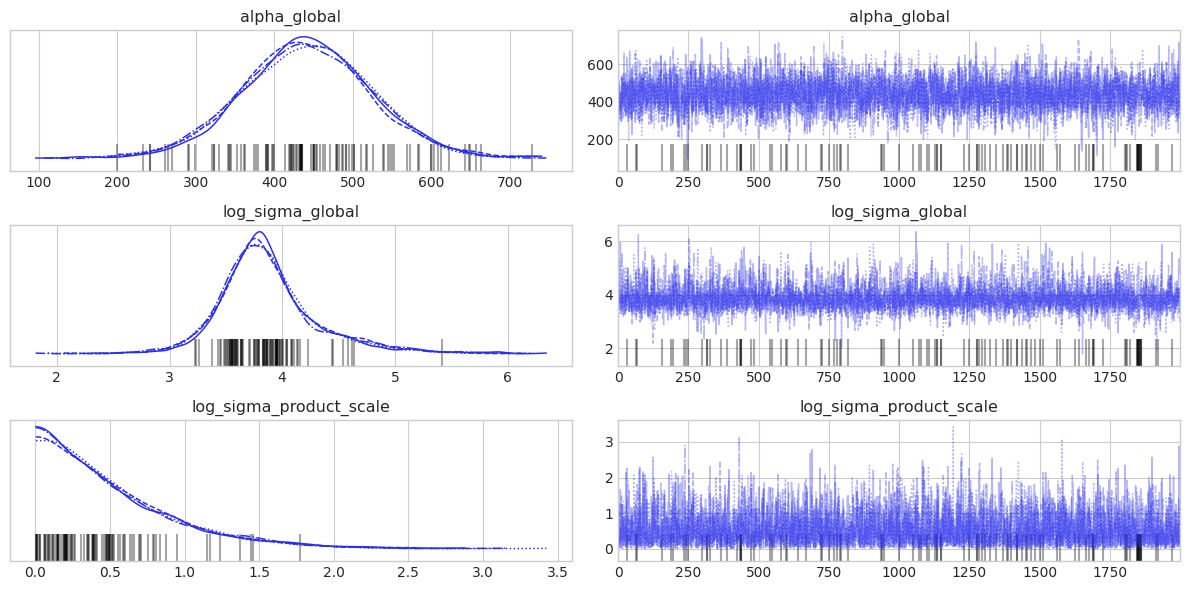

In [47]:
az.plot_trace(trace_4, var_names=["alpha_global", "log_sigma_global", "log_sigma_product_scale"])
plt.tight_layout()
plt.show()


In [48]:
predictions_4 = prediction_summary(ppc_4, model_df)
predictions_4.head()


,product,quantity,unit_price,.pred,.pred_lower_95,.pred_lower_66,.pred_upper_66,.pred_upper_95
0,Standard iPhone Case,444,38.79,434.305328,324.468873,382.109773,486.377745,541.094036
1,Standard iPhone Case,477,36.12,483.780091,378.854478,432.252663,534.612131,589.285987
2,Standard iPhone Case,656,27.62,645.989024,555.461776,603.378161,688.994879,736.374367
3,Standard iPhone Case,507,36.48,477.002333,373.789777,427.067423,527.340219,580.841007
4,Standard iPhone Case,513,37.50,457.507609,348.845407,407.267325,508.384499,561.520688


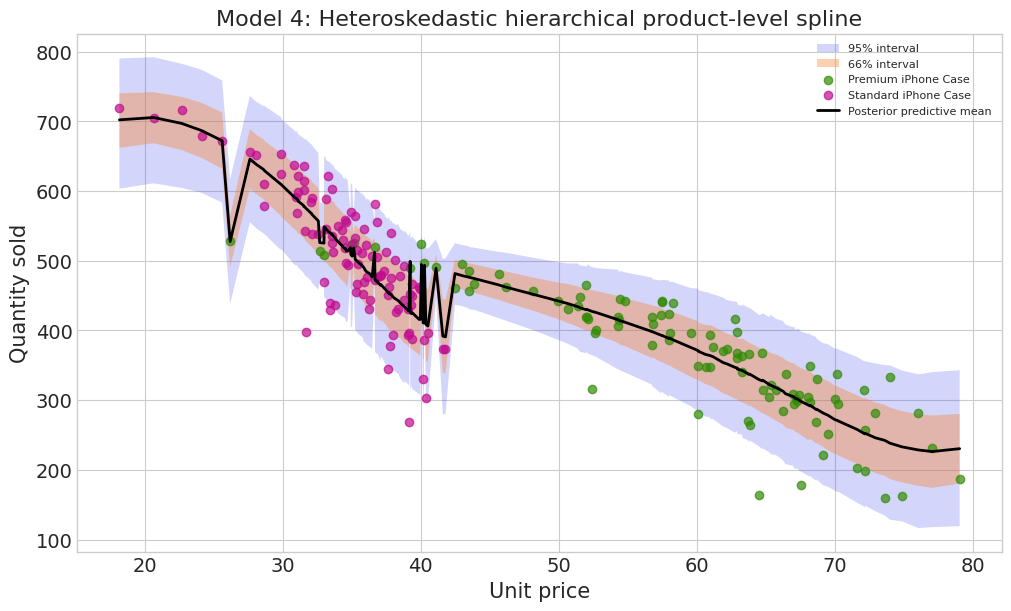

In [50]:
plot_predictions(predictions_4, "Model 4: Heteroskedastic hierarchical product-level spline")

/var/folders/qm/sbby5mpx22g9cm6655g9bwcw0000gn/T/ipykernel_5381/3627169406.py:53: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


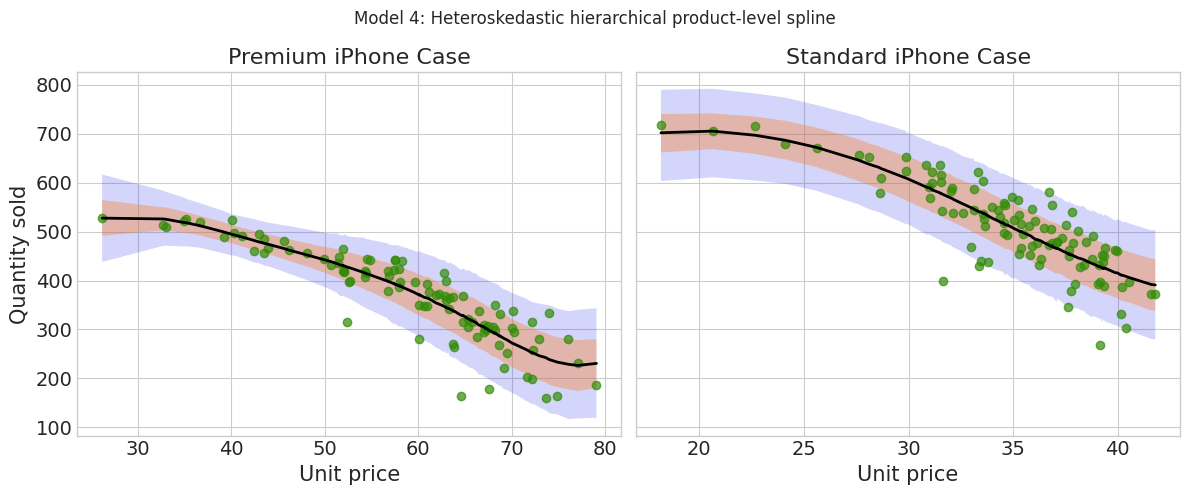

In [49]:
plot_predictions(predictions_4, "Model 4: Heteroskedastic hierarchical product-level spline", facet=True)


- we want to use this for a pricing strategy, 
- we are going to use this bayesian model to optimise and select the correct prices for both products using the ranges
- 90% of the time we're gonna be above the lower line. we want to find a point on that line the revenue maximising price (unit_price*quantity)
- on the price if we draw a line parallel to the y-axis that is going to be the prediction/ estimation (we will have a price that minimises the risk)

Model 4 separates two ideas: the expected demand curve and the volatility around that curve.

The demand spline estimates the average quantity expected at each price. The sigma spline estimates how noisy quantity is around that average at each price. The shaded intervals are posterior predictive intervals, so they include both uncertainty in the fitted demand curve and the learned residual volatility.

This matters for pricing because two prices can have similar expected demand but different downside risk. A price range with wider predicted volatility may be less attractive if the business wants more reliable sales outcomes.

In [52]:
# sigma_summary = az.summary(trace_4, var_names=["sigma_product_at_mean_price", "log_sigma_price_slope"])
sigma_summary = az.summary(trace_4, var_names=["sigma_product_at_mean_price"])
sigma_summary


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
sigma_product_at_mean_price[0],40.427,9.340,22.812,57.523,0.143,0.101,4180.0,3046.0,1.0
sigma_product_at_mean_price[1],45.296,12.861,23.296,70.335,0.160,0.113,6265.0,5363.0,1.0


In [53]:
trace_4.to_netcdf(MODELS_DIR / "notebook_model4_heteroskedastic_trace.nc")
predictions_4.to_csv(MODELS_DIR / "notebook_model4_heteroskedastic_predictions.csv", index=False)
print("Saved notebook Model 4 outputs.")


Saved notebook Model 4 outputs.


## Interpretation

Model 4 separates two ideas: the expected demand curve and the volatility around that curve. This is helpful when business decisions should account for both expected sales and uncertainty by product.


## Price Optimisation 

In [54]:
predictions_4

,product,quantity,unit_price,.pred,.pred_lower_95,.pred_lower_66,.pred_upper_66,.pred_upper_95
0,Standard iPhone Case,444,38.79,434.305328,324.468873,382.109773,486.377745,541.094036
1,Standard iPhone Case,477,36.12,483.780091,378.854478,432.252663,534.612131,589.285987
2,Standard iPhone Case,656,27.62,645.989024,555.461776,603.378161,688.994879,736.374367
3,Standard iPhone Case,507,36.48,477.002333,373.789777,427.067423,527.340219,580.841007
4,Standard iPhone Case,513,37.50,457.507609,348.845407,407.267325,508.384499,561.520688
...,...,...,...,...,...,...,...,...
192,Premium iPhone Case,280,60.10,371.097746,283.561874,328.422394,413.432821,460.224369
193,Premium iPhone Case,269,68.65,286.508744,184.182402,237.689547,334.560272,390.546348
194,Premium iPhone Case,439,58.26,386.667588,304.677211,346.810020,426.411268,469.449148
195,Premium iPhone Case,368,64.75,327.662829,229.535597,281.341575,373.965658,423.984934


In [55]:
predictions_4['sales_worst_case'] = predictions_4['unit_price'] * predictions_4['.pred_lower_95']
predictions_4['sales_best_case'] = predictions_4['unit_price'] * predictions_4['.pred_upper_95']
predictions_4['sales_most_likely'] = predictions_4['unit_price'] * predictions_4['.pred']

In [59]:
# for each product find the price that gives maximum worst case scenario
worst_case_price_idx = predictions_4.groupby("product", observed=True)["sales_worst_case"].idxmax()

worst_case_price_recommendations = (
    predictions_4.loc[
        worst_case_price_idx,
        [
            "product",
            "unit_price",
            ".pred_lower_95",
            ".pred",
            ".pred_upper_95",
            "sales_worst_case",
            "sales_most_likely",
            "sales_best_case",
        ],
    ]
    .sort_values("product")
    .reset_index(drop=True)
)

worst_case_price_recommendations

,product,unit_price,.pred_lower_95,.pred,.pred_upper_95,sales_worst_case,sales_most_likely,sales_best_case
0,Premium iPhone Case,49.92,386.809197,442.597615,498.238845,19309.515110,22094.472925,24872.083126
1,Standard iPhone Case,29.90,516.762011,609.215457,703.265586,15451.184127,18215.542178,21027.641019


Using a price of 29.90 for the standard case, we should get:
- most likely: 18215.542178 per week
- 


and 49.92 for the premium case:
- most likely: 22094.472925

This is how we price to minimise the worst case scenario

The organisation is able to understand their confidence, which helps us know how to price products

We just single-handedly discovered a framework for understanding downside risk in any bayesian model